# Task 1: Topic Proposal / Analysis Plan

## 1.1 Overall Analytical Objective

The overall goal of our project is to analyze the urban crime dataset provided by our professor to better understand patterns in recorded crime incidents from 2020 through 2024. Specifically, we want to investigate whether certain crime types are more common in specific districts, how the number of recorded incidents has changed over these 5 years, and whether arrest percentages differ depending on the type of crime. By examining these relationships, we hope to identify meaningful trends and differences that may not be obvious when looking at individual incidents. Our findings will provide a better understanding of how crime types, districts, time, and arrests are related within the provided dataset.

## 1.2 Research Questions

**Research Question 1:**

Is there a relationship between crime types and the districts in which they occur?

**Research Question 2:**

How has the number of recorded crime incidents changed from 2020 through 2024?

**Research Question 3:**

How does the percentage of incidents involving an arrest differ across crime types?

# Task 2: Data Loading, Provenance, and Preparation.

## 2.1 Loading the original Dataset

In [1]:
import pandas as pd

df_raw = pd.read_csv("IE6400_Project1_UrbanCrime_Instructional.csv")

In [2]:
print("Rows and Columns:", df_raw.shape)

df_raw.head()

Rows and Columns: (28100, 11)


,incident_id,incident_datetime,primary_type,description,location_description,arrest,domestic,district,community_area,x_coordinate,y_coordinate
0,10000001,2023-08-07 10:36:00,CRIMINAL DAMAGE,TO PROPERTY,RESIDENCE,False,False,11.0,23.0,1186749.0,1867051.0
1,10000002,2020-06-04 19:13:00,THEFT,OVER $500,STREET,False,No,8.0,3.0,1149071.0,1867601.0
2,10000003,2024-12-26 11:58:00,THEFT,OVER $500,STREET,False,False,12.0,13.0,1167221.0,1875323.0
3,10000004,2024-02-29 13:10:00,DECEPTIVE PRACTICE,FINANCIAL IDENTITY THEFT,SMALL RETAIL STORE,False,False,9.0,17.0,1185045.0,1864208.0
4,10000005,2022-05-22 15:27:00,THEFT,RETAIL THEFT,NaN,False,False,3.0,6.0,1205420.0,1849480.0


**We used Pandas to load the original CSV dataset provided by our professor through Canvas. After loading the dataset, we confirmed that it contained 28,100 rows and 11 columns. We also displayed the first five rows to make sure the dataset loaded correctly.**

## 2.2 Dataset Source & Provenance

The dataset, named IE6400_Project1_UrbanCrime_Instructional.csv, was provided by our professor, Sivarit Sultornsanee, for the course IE6400: Foundations for Data Analytics Engineering, Fall 2026. This is an instructional dataset, not official police records, and it is being used to help us apply what we have learned throughout the course. Our professor also provided the City of Chicago Crime Data Portal as a public reference, but we did not download our dataset from there.

## 2.3 Preserving the Original Dataset

We created a copy of the original dataset so we could make the necessary changes during cleaning while keeping the original data unchanged. This also allows us to compare the original dataset with the cleaned version to see what changes were made. If any mistakes occurred during the cleaning process, we could easily go back to the original dataset without losing any information.

# Task 3: Data Inspection

## 3.1 General Dataset Overview

In [3]:
df_raw.shape

(28100, 11)

In [4]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 28100 entries, 0 to 28099
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   incident_id           28100 non-null  int64  
 1   incident_datetime     28100 non-null  str    
 2   primary_type          28100 non-null  str    
 3   description           28100 non-null  str    
 4   location_description  27597 non-null  str    
 5   arrest                28100 non-null  str    
 6   domestic              28100 non-null  str    
 7   district              27932 non-null  float64
 8   community_area        27764 non-null  float64
 9   x_coordinate          27316 non-null  float64
 10  y_coordinate          27312 non-null  float64
dtypes: float64(4), int64(1), str(6)
memory usage: 2.4 MB


In [5]:
df_raw.nunique(dropna=False)

incident_id             28000
incident_datetime       27797
primary_type               20
description                21
location_description       21
arrest                      4
domestic                    4
district                   13
community_area             31
x_coordinate            22119
y_coordinate            21574
dtype: int64

In [6]:
df_raw.isna().sum()

incident_id               0
incident_datetime         0
primary_type              0
description               0
location_description    503
arrest                    0
domestic                  0
district                168
community_area          336
x_coordinate            784
y_coordinate            788
dtype: int64

In [7]:
df_raw["district"].value_counts(dropna=False).sort_index()

district
1.0     2281
2.0     1977
3.0     2497
4.0     2274
5.0     1964
6.0     2235
7.0     2770
8.0     2477
9.0     2210
10.0    2505
11.0    2277
12.0    2465
NaN      168
Name: count, dtype: int64

In [8]:
df_raw["community_area"].value_counts(dropna=False).sort_index()

community_area
1.0     995
2.0     923
3.0     904
4.0     913
5.0     905
6.0     915
7.0     972
8.0     875
9.0     931
10.0    994
11.0    893
12.0    934
13.0    960
14.0    940
15.0    885
16.0    922
17.0    897
18.0    917
19.0    938
20.0    896
21.0    919
22.0    922
23.0    914
24.0    872
25.0    983
26.0    966
27.0    893
28.0    925
29.0    915
30.0    946
NaN     336
Name: count, dtype: int64

**The Urban Crime dataset contains 28,100 rows and 11 columns, with each row representing a specific crime incident. Each row provides information about the type of crime, a brief description of the incident, the location, whether an arrest was made, whether the crime was classified as domestic, the district and community area where it occurred, and its X and Y coordinates. The dataset covers incidents from 2020 through 2024.**

## 3.2 Analytical Roles of Dataset Variables

| Column | Analytical Role | Explanation |
|---|---|---|
| incident_id | Identifier | Identifies each incident |
| incident_datetime | Temporal | Date and time of the incident |
| primary_type | Categorical | General crime category |
| description | Categorical | Specific description of the crime |
| location_description | Categorical | Type of location |
| arrest | Binary categorical | Whether an arrest was made |
| domestic | Binary categorical | Whether the incident was domestic |
| district | Geographic categorical code | District associated with the incident |
| community_area | Geographic categorical code | Community area associated with the incident |
| x_coordinate | Numerical spatial | Horizontal geographic coordinate |
| y_coordinate | Numerical spatial | Vertical geographic coordinate |

### Identifiers & Categorical Variables vs Continuous Numerical Variables 

Even though incident_id, district, and community_area are represented by numbers, they should not be treated as continuous numerical variables because they are used to identify specific incidents or locations. For example, someone being in District 12 does not mean that District 12 is greater than District 5 in terms of crime, and the same idea applies to community areas. The incident_id is just a unique number assigned to each incident so we can identify it in the dataset. Because of this, calculating the average of these numbers would not tell us anything meaningful about crime.

## 3.3 Data Quality Findings

### Data Quality Finding 1 - Inconsistent Boolean Values 


In [9]:
df_raw["domestic"].value_counts(dropna=False)

domestic
False    25182
True      2838
No          74
Yes          6
Name: count, dtype: int64

In [10]:
df_raw["arrest"].value_counts(dropna=False)

arrest
False    24164
True      3856
No          61
Yes         19
Name: count, dtype: int64

**The arrest & Domestic columns contain inconsistent representations of boolean values. Both collumns ue "True/False" and "Yes/No" to represent the same information. We will change these values to ONLY "True/False" to ensure consistency during analysis. I do not need to remove anything to correct this issue.**

### Data Quality Finding 2 - Inconsistent Crime Categories 


In [11]:
df_raw["primary_type"].value_counts(dropna=False)

primary_type
THEFT                  6707
BATTERY                4717
CRIMINAL DAMAGE        3958
ASSAULT                2819
BURGLARY               2204
MOTOR VEHICLE THEFT    1954
DECEPTIVE PRACTICE     1761
OTHER OFFENSE          1411
ROBBERY                1331
NARCOTICS              1089
theft                    40
battery                  25
assault                  19
criminal damage          18
burglary                 12
deceptive practice       11
motor vehicle theft       9
other offense             6
narcotics                 5
robbery                   4
Name: count, dtype: int64

**After looking at the primary_type column, I noticed that some of the crime categories were repeated because they were written in both uppercase and lowercase letters. Even though they represent the same type of crime, Python counts them as separate categories. There are currently 20 different labels, but there should only be 10. When cleaning the data, I will make all the categories uppercase so they are counted together correctly.**

In [12]:
df_raw["description"].value_counts(dropna=False)

description
SIMPLE                            3003
FROM BUILDING                     2322
RETAIL THEFT                      2232
OVER $500                         2193
TO PROPERTY                       2028
TO VEHICLE                        1948
AGGRAVATED                        1631
DOMESTIC BATTERY SIMPLE           1525
AGGRAVATED - HANDGUN              1421
UNLAWFUL ENTRY                    1137
FORCIBLE ENTRY                    1079
AUTOMOBILE                        1026
TRUCK / BUS / MOTOR HOME           937
CREDIT CARD FRAUD                  896
FINANCIAL IDENTITY THEFT           876
OTHER VEHICLE OFFENSE              728
HARASSMENT BY TELEPHONE            689
ARMED - HANDGUN                    676
STRONG ARM - NO WEAPON             659
POSSESS - CONTROLLED SUBSTANCE     577
POSSESS - CANNABIS                 517
Name: count, dtype: int64

In [13]:
df_raw["description"].nunique()

21

### Data Quality Finding 3 - Duplicate Rows

In [14]:
df_raw.duplicated().sum()

np.int64(99)

In [15]:
df_raw[df_raw.duplicated(keep=False)].sort_values("incident_id").head(10)

,incident_id,incident_datetime,primary_type,description,location_description,arrest,domestic,district,community_area,x_coordinate,y_coordinate
400,10000401,2024-12-19 21:57:00,BATTERY,DOMESTIC BATTERY SIMPLE,SMALL RETAIL STORE,False,True,3.0,16.0,1203968.0,1843952.0
28094,10000401,2024-12-19 21:57:00,BATTERY,DOMESTIC BATTERY SIMPLE,SMALL RETAIL STORE,False,True,3.0,16.0,1203968.0,1843952.0
28092,10000591,2024-05-26 07:45:00,THEFT,FROM BUILDING,APARTMENT,False,False,8.0,29.0,1153148.0,1865640.0
590,10000591,2024-05-26 07:45:00,THEFT,FROM BUILDING,APARTMENT,False,False,8.0,29.0,1153148.0,1865640.0
1080,10001081,2020-07-30 17:56:00,THEFT,FROM BUILDING,CTA PLATFORM,False,False,5.0,4.0,1182017.0,1851425.0
28078,10001081,2020-07-30 17:56:00,THEFT,FROM BUILDING,CTA PLATFORM,False,False,5.0,4.0,1182017.0,1851425.0
28077,10001346,2022-01-07 07:31:00,CRIMINAL DAMAGE,TO VEHICLE,STREET,False,False,1.0,3.0,1170793.0,1845508.0
1345,10001346,2022-01-07 07:31:00,CRIMINAL DAMAGE,TO VEHICLE,STREET,False,False,1.0,3.0,1170793.0,1845508.0
1646,10001647,2023-08-21 19:23:00,THEFT,OVER $500,RESTAURANT,False,False,6.0,20.0,1177719.0,1858407.0
28004,10001647,2023-08-21 19:23:00,THEFT,OVER $500,RESTAURANT,False,False,6.0,20.0,1177719.0,1858407.0


**After checking the dataset for duplicates, I found 99 rows that were repeated. I looked at some of these records and noticed that they had the same incident ID, date, crime type, location, and other information. Since these rows are completely identical, they are definitely duplicate entries and NOT separate crimes. When cleaning the dataset, I will remove these extra rows so they don't affect the results of our analysis.**

### Data Quality Finding 4 - Hidden Duplicate Record

In [16]:
df_raw["incident_id"].duplicated().sum()

np.int64(100)

In [17]:
duplicates = df_raw[
    df_raw["incident_id"].duplicated(keep=False)
]

duplicates[
    ~duplicates.duplicated(keep=False)
]

,incident_id,incident_datetime,primary_type,description,location_description,arrest,domestic,district,community_area,x_coordinate,y_coordinate
22387,10022388,2022-01-20 23:49:00,THEFT,RETAIL THEFT,RESTAURANT,True,False,9.0,8.0,1179402.0,NaN
28068,10022388,2022-01-20 23:49:00,THEFT,RETAIL THEFT,RESTAURANT,True,No,9.0,8.0,1179402.0,NaN


**After checking for repeated IDs, we found 100 repeated IDs compared to the previous 99 exact duplicate rows. After looking into the extra record, I noticed that the domestic column had False in one entry and No in the other, even though they mean the same thing. This showed me that inconsistent formatting can cause Python to miss duplicates. When cleaning the data, I will correct the Boolean columns first and then remove the duplicates so I don't miss any repeated records.**

### Data Quality Finding 5 - Missing Dates

In [18]:
df_raw["incident_datetime"].value_counts().head(10)

incident_datetime
not recorded           35
2020-05-27 02:57:00     2
2024-07-13 05:35:00     2
2024-11-29 00:08:00     2
2021-12-28 15:47:00     2
2024-12-19 21:57:00     2
2023-07-03 04:43:00     2
2023-10-26 01:39:00     2
2021-10-25 10:07:00     2
2024-05-26 07:45:00     2
Name: count, dtype: int64

In [19]:
df_raw[
    df_raw["incident_datetime"] == "not recorded"
].shape[0]

35

In [20]:
dates = pd.to_datetime(df_raw["incident_datetime"], errors="coerce")

print("Earliest date:", dates.min())
print("Latest date:", dates.max())
print("Invalid or missing dates:", dates.isna().sum())

Earliest date: 2020-01-01 03:49:00
Latest date: 2024-12-31 22:09:00
Invalid or missing dates: 35


**After checking the incident_datetime column, I found 35 records where the date was entered as "not recorded." Since these records don't have an actual date, I won't be able to use them when analyzing crime trends over time. However, I plan to keep them for other analyses that don't require a date. During cleaning, I will convert these values into missing datetime values instead of making up dates.**

### Data Quality Finding 6 - Invalid Coordinates 

In [21]:
df_raw[["x_coordinate", "y_coordinate"]].describe()

,x_coordinate,y_coordinate
count,2.731600e+04,2.731200e+04
mean,1.180208e+06,1.857322e+06
std,3.966233e+04,5.830979e+04
min,0.000000e+00,-9.990000e+02
25%,1.166576e+06,1.847382e+06
50%,1.181578e+06,1.858960e+06
75%,1.195932e+06,1.870326e+06
max,1.226535e+06,1.908283e+06


In [22]:
df_raw[
    (df_raw["x_coordinate"] == 0) |
    (df_raw["y_coordinate"] == -999)
]

,incident_id,incident_datetime,primary_type,description,location_description,arrest,domestic,district,community_area,x_coordinate,y_coordinate
95,10000096,2020-05-27 02:57:00,ROBBERY,STRONG ARM - NO WEAPON,STREET,False,False,11.0,23.0,0.0,1866320.0
221,10000222,2022-04-30 17:28:00,THEFT,FROM BUILDING,CTA PLATFORM,False,False,4.0,28.0,0.0,1857196.0
259,10000260,2021-11-06 01:56:00,OTHER OFFENSE,OTHER VEHICLE OFFENSE,GROCERY FOOD STORE,False,False,3.0,14.0,0.0,1834905.0
396,10000397,2020-10-21 06:06:00,MOTOR VEHICLE THEFT,TRUCK / BUS / MOTOR HOME,SIDEWALK,False,False,6.0,12.0,1186636.0,-999.0
952,10000953,2021-04-16 15:03:00,THEFT,FROM BUILDING,CTA PLATFORM,False,False,9.0,17.0,0.0,1864544.0
1147,10001148,2023-07-28 11:02:00,BATTERY,AGGRAVATED,RESTAURANT,False,False,6.0,18.0,0.0,1856507.0
1299,10001300,2023-02-02 11:22:00,THEFT,OVER $500,GROCERY FOOD STORE,True,False,2.0,5.0,0.0,1845030.0
1630,10001631,2023-02-07 14:00:00,OTHER OFFENSE,OTHER VEHICLE OFFENSE,STREET,False,False,10.0,18.0,1191731.0,-999.0
1686,10001687,2024-05-29 21:07:00,CRIMINAL DAMAGE,TO VEHICLE,RESTAURANT,False,False,NaN,25.0,1179953.0,-999.0
2921,10002922,2022-11-05 01:23:00,ASSAULT,SIMPLE,SMALL RETAIL STORE,False,False,1.0,2.0,0.0,1846499.0


**After looking at the x_coordinate and y_coordinate columns, I noticed that some records had unusual values like 0 and -999. These values are very different from the other coordinates and appear to be invalid. I found 50 records with these suspicious values. When cleaning the dataset, I plan to replace these values with missing values instead of deleting the entire row, because the other information can still be used for different types of crime analysis.**

In [23]:
print("Both coordinates missing:",
      (df_raw["x_coordinate"].isna() &
       df_raw["y_coordinate"].isna()).sum())

print("Only X missing:",
      (df_raw["x_coordinate"].isna() &
       df_raw["y_coordinate"].notna()).sum())

print("Only Y missing:",
      (df_raw["x_coordinate"].notna() &
       df_raw["y_coordinate"].isna()).sum())

Both coordinates missing: 20
Only X missing: 764
Only Y missing: 768


**After looking further into the missing coordinates, I found that 20 records were missing both X and Y coordinates, 764 were missing only X, and 768 were missing only Y. This means 1,552 records were missing at least one coordinate. Since both coordinates are needed to identify an exact location, I plan to keep these records but exclude them from analyses that require exact geographic locations.**

### Data Quality Finding 7 - Inconsistent Location Descriptions 

In [24]:
df_raw["location_description"].value_counts(dropna=False)

location_description
STREET                        6227
RESIDENCE                     4938
APARTMENT                     3803
SIDEWALK                      2736
PARKING LOT / GARAGE          2547
SMALL RETAIL STORE            1917
GROCERY FOOD STORE            1678
RESTAURANT                    1393
CTA PLATFORM                  1160
SCHOOL, PUBLIC, BUILDING      1078
NaN                            503
 STREET                         30
 RESIDENCE                      20
 APARTMENT                      18
 RESTAURANT                     12
 SIDEWALK                       10
 GROCERY FOOD STORE             10
 PARKING LOT / GARAGE            9
 SMALL RETAIL STORE              4
 SCHOOL, PUBLIC, BUILDING        4
 CTA PLATFORM                    3
Name: count, dtype: int64

**After looking at the location_description column, I noticed that some locations were being counted twice because they had extra spaces at the beginning and end of the text. This causes Python to treat them as separate categories even though they represent the same location type. There are currently 20 different nonmissing labels, but there should only be 10. I also found 503 missing values. When cleaning the data, I plan to remove the extra spaces so the locations are grouped correctly while keeping the records with missing locations for analyses that don't need that information.**

In [25]:
text_columns = [
    "primary_type",
    "description",
    "location_description",
    "arrest",
    "domestic"
]

for col in text_columns:
    print(col)
    print(df_raw[col].unique())
    print()

primary_type
<StringArray>
[    'CRIMINAL DAMAGE',               'THEFT',  'DECEPTIVE PRACTICE',
             'ASSAULT',            'BURGLARY', 'MOTOR VEHICLE THEFT',
             'BATTERY',       'OTHER OFFENSE',             'ROBBERY',
           'NARCOTICS',               'theft',     'criminal damage',
       'other offense',             'robbery',            'burglary',
             'battery',             'assault',           'narcotics',
  'deceptive practice', 'motor vehicle theft']
Length: 20, dtype: str

description
<StringArray>
[                   'TO PROPERTY',                      'OVER $500',
       'FINANCIAL IDENTITY THEFT',                   'RETAIL THEFT',
                  'FROM BUILDING',              'CREDIT CARD FRAUD',
                         'SIMPLE',                 'UNLAWFUL ENTRY',
                     'AUTOMOBILE',        'DOMESTIC BATTERY SIMPLE',
                 'FORCIBLE ENTRY',       'TRUCK / BUS / MOTOR HOME',
                     'AGGRAVATED',        

# Task 4: Data Cleaning and Transformation

## 4.1 Creating a Working Copy

In [26]:
df_clean = df_raw.copy()

print("Original dataset:", df_raw.shape)
print("Working dataset:", df_clean.shape)

Original dataset: (28100, 11)
Working dataset: (28100, 11)


## 4.2 Standardizing Boolean Values

In [27]:
print("Arrest values:")
print(df_clean["arrest"].value_counts(dropna=False))

print("\nDomestic values:")
print(df_clean["domestic"].value_counts(dropna=False))

Arrest values:
arrest
False    24164
True      3856
No          61
Yes         19
Name: count, dtype: int64

Domestic values:
domestic
False    25182
True      2838
No          74
Yes          6
Name: count, dtype: int64


In [28]:
df_clean["arrest"] = df_clean["arrest"].replace({
    "Yes": "True",
    "No": "False"
})

df_clean["arrest"].value_counts(dropna=False)

arrest
False    24225
True      3875
Name: count, dtype: int64

In [29]:
df_clean["domestic"] = df_clean["domestic"].replace({
    "Yes": "True",
    "No": "False"
})

df_clean["domestic"].value_counts(dropna=False)

domestic
False    25256
True      2844
Name: count, dtype: int64

In [30]:
df_clean["arrest"] = df_clean["arrest"].map({
    "True": True,
    "False": False
})

df_clean["domestic"] = df_clean["domestic"].map({
    "True": True,
    "False": False
})

print(df_clean[["arrest", "domestic"]].dtypes)

arrest      bool
domestic    bool
dtype: object


### Cleaning Summary: Arrest & Domestic Values

We were able to make the values within the arrest and domestic columns more consistent by changing all "Yes" values to "True" and all "No" values to "False". We also changed the data types of these columns from strings to Boolean values. This reduced each column from four different labels to two possible values, True and False. No records were removed during this cleaning process.

## 4.3 Standardizing the Primary Type Column (Capitalization)

In [31]:
df_clean["primary_type"].value_counts(dropna=False)

primary_type
THEFT                  6707
BATTERY                4717
CRIMINAL DAMAGE        3958
ASSAULT                2819
BURGLARY               2204
MOTOR VEHICLE THEFT    1954
DECEPTIVE PRACTICE     1761
OTHER OFFENSE          1411
ROBBERY                1331
NARCOTICS              1089
theft                    40
battery                  25
assault                  19
criminal damage          18
burglary                 12
deceptive practice       11
motor vehicle theft       9
other offense             6
narcotics                 5
robbery                   4
Name: count, dtype: int64

In [32]:
df_clean["primary_type"] = df_clean["primary_type"].str.upper()

df_clean["primary_type"].value_counts(dropna=False)

primary_type
THEFT                  6747
BATTERY                4742
CRIMINAL DAMAGE        3976
ASSAULT                2838
BURGLARY               2216
MOTOR VEHICLE THEFT    1963
DECEPTIVE PRACTICE     1772
OTHER OFFENSE          1417
ROBBERY                1335
NARCOTICS              1094
Name: count, dtype: int64

### Cleaning Summary: Primary Type

After inspecting the primary_type column, I noticed that some crime categories were written in lowercase while others were uppercase. This resulted in inconsistencies within the column, so I used the .str.upper() method to change all lowercase crime categories to uppercase. This made the data more consistent and reduced the number of unique category labels from 20 to 10, since the other 10 labels represented the same crime categories with different capitalization. This will help ensure that incidents are grouped correctly during analysis.

## 4.4 Standardizing the "Location Description" Column

In [33]:
df_clean["location_description"].value_counts(dropna=False)

location_description
STREET                        6227
RESIDENCE                     4938
APARTMENT                     3803
SIDEWALK                      2736
PARKING LOT / GARAGE          2547
SMALL RETAIL STORE            1917
GROCERY FOOD STORE            1678
RESTAURANT                    1393
CTA PLATFORM                  1160
SCHOOL, PUBLIC, BUILDING      1078
NaN                            503
 STREET                         30
 RESIDENCE                      20
 APARTMENT                      18
 RESTAURANT                     12
 SIDEWALK                       10
 GROCERY FOOD STORE             10
 PARKING LOT / GARAGE            9
 SMALL RETAIL STORE              4
 SCHOOL, PUBLIC, BUILDING        4
 CTA PLATFORM                    3
Name: count, dtype: int64

In [34]:
df_clean["location_description"] = df_clean["location_description"].str.strip()

df_clean["location_description"].value_counts(dropna=False)

location_description
STREET                      6257
RESIDENCE                   4958
APARTMENT                   3821
SIDEWALK                    2746
PARKING LOT / GARAGE        2556
SMALL RETAIL STORE          1921
GROCERY FOOD STORE          1688
RESTAURANT                  1405
CTA PLATFORM                1163
SCHOOL, PUBLIC, BUILDING    1082
NaN                          503
Name: count, dtype: int64

### Cleaning Summary: Location Description

After inspecting the location_description column, I noticed that some locations were being counted separately because there were extra spaces at the beginning and end of certain values. This caused Python to interpret them as different categories even though they represented the same location. I used the .str.strip() method to remove the extra spaces so Python could group the locations correctly. This reduced the number of nonmissing location categories from 20 to 10, while keeping the 503 missing values unchanged. No records were removed during this process.

## 4.5 Converting Incident Dates and Creating Temporal Variables

In [35]:
df_clean["incident_datetime"] = pd.to_datetime(
    df_clean["incident_datetime"],
    errors="coerce"
)

print(df_clean["incident_datetime"].dtype)
print("Missing dates:", df_clean["incident_datetime"].isna().sum())

datetime64[us]
Missing dates: 35


In [36]:
df_clean["year"] = df_clean["incident_datetime"].dt.year
df_clean["month"] = df_clean["incident_datetime"].dt.month
df_clean["day_of_week"] = df_clean["incident_datetime"].dt.day_name()
df_clean["hour"] = df_clean["incident_datetime"].dt.hour

df_clean[["incident_datetime", "year", "month", "day_of_week", "hour"]].head()

,incident_datetime,year,month,day_of_week,hour
0,2023-08-07 10:36:00,2023.0,8.0,Monday,10.0
1,2020-06-04 19:13:00,2020.0,6.0,Thursday,19.0
2,2024-12-26 11:58:00,2024.0,12.0,Thursday,11.0
3,2024-02-29 13:10:00,2024.0,2.0,Thursday,13.0
4,2022-05-22 15:27:00,2022.0,5.0,Sunday,15.0


In [37]:
df_clean.loc[
    df_clean["incident_datetime"].isna(),
    ["incident_datetime", "year", "month", "day_of_week", "hour"]
].head()

,incident_datetime,year,month,day_of_week,hour
1785,NaT,NaN,NaN,NaN,NaN
2977,NaT,NaN,NaN,NaN,NaN
3878,NaT,NaN,NaN,NaN,NaN
4023,NaT,NaN,NaN,NaN,NaN
4080,NaT,NaN,NaN,NaN,NaN


### Cleaning Summary: Incident Dates and Temporal Variables

After inspecting the incident_datetime column, I found 35 records that did not contain a valid date. I used pd.to_datetime() with errors="coerce" to convert the column into datetime values and replace entries such as "not recorded" with NaT. Similar to how missing values were handled in the location_description column, this allows us to identify information that was not recorded instead of making up values. I also created four new columns: year, month, day_of_week, and hour, which will help us analyze crime patterns over time. We kept all 35 incidents because their other information can still be useful when analyzing crime categories and arrests, but we will exclude them from analyses that require valid dates.

## 4.6 Handling Missing and Invalid Values

### 4.6.1 Assessing Missing Values

In [38]:
df_clean.isna().sum()

incident_id               0
incident_datetime        35
primary_type              0
description               0
location_description    503
arrest                    0
domestic                  0
district                168
community_area          336
x_coordinate            784
y_coordinate            788
year                     35
month                    35
day_of_week              35
hour                     35
dtype: int64

In [39]:
print("Missing X coordinates:", df_clean["x_coordinate"].isna().sum())
print("Missing Y coordinates:", df_clean["y_coordinate"].isna().sum())

print("X coordinates equal to 0:", (df_clean["x_coordinate"] == 0).sum())
print("Y coordinates equal to -999:", (df_clean["y_coordinate"] == -999).sum())

Missing X coordinates: 784
Missing Y coordinates: 788
X coordinates equal to 0: 25
Y coordinates equal to -999: 25


### 4.6.2 Cleaning Invalid Coordinates

In [40]:
df_clean["x_coordinate"] = df_clean["x_coordinate"].replace(0, float("nan"))

df_clean["y_coordinate"] = df_clean["y_coordinate"].replace(-999, float("nan"))

In [41]:
print("Missing X coordinates:", df_clean["x_coordinate"].isna().sum())
print("Missing Y coordinates:", df_clean["y_coordinate"].isna().sum())

print("Invalid X values remaining:", (df_clean["x_coordinate"] == 0).sum())
print("Invalid Y values remaining:", (df_clean["y_coordinate"] == -999).sum())

Missing X coordinates: 809
Missing Y coordinates: 813
Invalid X values remaining: 0
Invalid Y values remaining: 0


In [42]:
df_clean[["x_coordinate", "y_coordinate"]].describe()

,x_coordinate,y_coordinate
count,2.729100e+04,2.728700e+04
mean,1.181290e+06,1.859024e+06
std,1.724423e+04,1.536916e+04
min,1.134633e+06,1.815182e+06
25%,1.166628e+06,1.847414e+06
50%,1.181599e+06,1.858990e+06
75%,1.195943e+06,1.870343e+06
max,1.226535e+06,1.908283e+06


#### Cleaning Summary: Invalid Coordinates

After inspecting the x_coordinate and y_coordinate columns, I discovered 25 X coordinates recorded as 0 and 25 Y coordinates recorded as -999. These values were significantly different from the other coordinates in the dataset, so I treated them as invalid values that likely represented missing information. I used the .replace() method to convert these values into NaN, allowing Python to recognize them as missing rather than actual coordinates. We kept these incidents because their other information is still useful for analyzing crime categories and arrests, but we cannot use incomplete coordinates to determine their exact locations.

### 4.6.3 Missing Value Treatment Summary

After looking at the missing values in our dataset, we decided to keep all the rows because they still contain useful information. Even if a row is missing a value in one column, we can still use the other information for our analysis. 
For columns like district and community_area, we kept the missing values as NaN instead of making up numbers. Even though these columns contain numbers, they represent categories, so using the mean or median would not make sense. Making up these values could also affect our results by assigning crimes to the wrong areas. 
We also kept the missing values in location_description and incident_datetime. When analyzing a specific column, we will leave out rows that are missing the information needed for that analysis.

## 4.7 Checking and Removing Duplicate Records

In [43]:
print("Exact duplicate rows:", df_clean.duplicated().sum())

print("Repeated incident IDs:", df_clean["incident_id"].duplicated().sum())

Exact duplicate rows: 100
Repeated incident IDs: 100


In [44]:
df_clean = df_clean.drop_duplicates()

print("Rows after cleaning:", df_clean.shape[0])
print("Exact duplicates remaining:", df_clean.duplicated().sum())
print("Repeated incident IDs remaining:", df_clean["incident_id"].duplicated().sum())

Rows after cleaning: 28000
Exact duplicates remaining: 0
Repeated incident IDs remaining: 0


### Cleaning Summary: Duplicate Records

After cleaning the dataset, I checked for duplicate records again and found 100 exact duplicates. Originally, we found 99 exact duplicates, but after changing the arrest and domestic columns from four different labels ("True", "False", "Yes", and "No") into two Boolean values (True and False), two previously different rows became identical. This increased the number of exact duplicates to 100. We then used the .drop_duplicates() method to remove the extra copies of these incidents, reducing our dataset from 28,100 rows to 28,000 rows. This was important because keeping duplicate incidents would cause us to count the same crimes more than once, which could affect our results when analyzing crime types, locations, and trends over time.

## 4.8 Before-and-After Data Quality Summary

In [45]:
print("Original rows:", df_raw.shape[0])
print("Cleaned rows:", df_clean.shape[0])

print("Original columns:", df_raw.shape[1])
print("Cleaned columns:", df_clean.shape[1])

print("Original duplicates:", df_raw.duplicated().sum())
print("Cleaned duplicates:", df_clean.duplicated().sum())

Original rows: 28100
Cleaned rows: 28000
Original columns: 11
Cleaned columns: 15
Original duplicates: 99
Cleaned duplicates: 0


In [46]:
print("Primary Type:")
print("Before:", df_raw["primary_type"].nunique())
print("After:", df_clean["primary_type"].nunique())

print("\nLocation Description:")
print("Before:", df_raw["location_description"].nunique())
print("After:", df_clean["location_description"].nunique())

Primary Type:
Before: 20
After: 10

Location Description:
Before: 20
After: 10


In [47]:
columns = [
    "incident_datetime",
    "location_description",
    "district",
    "community_area",
    "x_coordinate",
    "y_coordinate"
]

missing_summary = pd.DataFrame({
    "Before": df_raw[columns].isna().sum(),
    "After": df_clean[columns].isna().sum()
})

missing_summary

,Before,After
incident_datetime,0,35
location_description,503,501
district,168,168
community_area,336,336
x_coordinate,784,805
y_coordinate,788,807


In [48]:
summary = pd.DataFrame({
    "Check": [
        "Total Rows",
        "Total Columns",
        "Exact Duplicates",
        "Primary Type Categories",
        "Location Description Categories",
        "Missing Dates",
        "Missing X Coordinates",
        "Missing Y Coordinates"
    ],
    "Before": [
        28100, 11, 99, 20, 20, 0, 784, 788
    ],
    "After": [
        28000, 15, 0, 10, 10, 35, 805, 807
    ]
})

summary

,Check,Before,After
0,Total Rows,28100,28000
1,Total Columns,11,15
2,Exact Duplicates,99,0
3,Primary Type Categories,20,10
4,Location Description Categories,20,10
5,Missing Dates,0,35
6,Missing X Coordinates,784,805
7,Missing Y Coordinates,788,807


### Cleaning Results Summary

After cleaning the dataset, we were able to fix several problems. First, we removed 100 duplicate incidents, reducing the dataset from 28,100 rows to 28,000 rows. We also fixed the inconsistent categories in the primary_type and location_description columns, reducing both from 20 categories to 10. Lastly, some missing-value counts increased because we changed invalid values into NaN or NaT. This allowed Python to recognize these values as missing data instead of treating entries like "not recorded" or invalid coordinates as actual information.

### Scaling and Encoding Decisions

We decided not to apply scaling or encoding to our dataset at this stage because our planned analysis focuses on comparing crime categories, locations, and trends over time using charts and counts. Python can already work with these values without changing them into a different format. If we decide to use a machine learning model later that requires scaling or encoding, we can apply those methods when needed.

In [49]:
df_clean.to_csv("IE6400_Project1_Cleaned.csv", index=False)

# Task 5: Exploratory Data Analysis (EDA)

In this section, we use the cleaned dataset to answer Research Question 1-3. Each research question is answered with two figures, and each figure is designed to show one specific finding. For each question, we explain the purpose of the analysis, the method we used, the specific results, what the results mean, and the limitations.

## 5.0 EDA Setup

We continue using the cleaned dataset (df_clean) created in Task 4 of this notebook. The columns district, community_area, year, month, and hour are converted to nullable integer types to ensure they contain whole-number values while still allowing missing values. Each analysis excludes only the records missing the fields required for that specific research question. Research Question 1 uses the 27,832 records with a known district, while the time-based analyses use the 27,965 records with a valid date.

We also assign one fixed color to each crime type and use it in every figure. For example, theft is always blue, battery is always orange, and criminal damage is always green. This makes it easier for the reader to follow each category from one figure to the next.

In [50]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency

# Consistent formatting for all charts
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold"
})

# Convert whole-number columns to integers
for col in ["district", "community_area", "year", "month", "hour"]:
    df_clean[col] = df_clean[col].astype("Int64")

# Create datasets for specific research questions
df_geo = df_clean.dropna(subset=["district"]).copy()
df_time = df_clean.dropna(subset=["incident_datetime"]).copy()

# Order crime types from most common to least common
type_counts = df_clean["primary_type"].value_counts()
TYPE_ORDER = list(type_counts.index)

# Assign consistent colors to each crime type
TAB10 = plt.cm.tab10.colors
CRIME_COLORS = {
    crime: TAB10[i]
    for i, crime in enumerate(TYPE_ORDER)
}

# Make crime type labels easier to read
def label(crime):
    return crime.title()

# Verify setup
print("Cleaned dataset:", df_clean.shape)
print("Records with a known district:", len(df_geo))
print("Records with a valid date:", len(df_time))


Cleaned dataset: (28000, 15)
Records with a known district: 27832
Records with a valid date: 27965


## 5.1 Research Question 1: Is there a relationship between crime types and the districts in which they occur?

### (Q1) Figure 1: Crime-Type Ranking in Each District

### Purpose

The purpose of this analysis is to find out whether certain crime types are more common in some districts than in others. If there were a relationship, we would expect some districts to have a noticeably higher or lower share of specific crime types, such as a district where theft makes up a much larger part of its incidents than in the rest of the dataset.

### Method

We created a crosstab of crime type by district using the 27,832 incidents with a known district. Because districts record different numbers of incidents, we did not compare districts using raw counts. Instead, we calculated percentages within each district, which show what share of a district's incidents belongs to each crime type. We then compared these percentages with the overall share of each crime type. To test whether the differences are larger than random variation, we used two methods: a chi-square test of independence, and a permutation test, where we randomly shuffled the district labels 1,000 times to see how large the differences would be by chance alone.

### Counts vs Percentages 

In [51]:
# Counts vs. percentages: districts record different NUMBERS of incidents,
# So we compare the crime mix using PERCENTAGES within each district.
ct = pd.crosstab(df_geo["primary_type"], df_geo["district"]).loc[TYPE_ORDER]
district_totals = ct.sum(axis=0)
col_pct = ct.div(district_totals, axis=1) * 100           # % of each district's incidents
overall_pct = ct.sum(axis=1) / ct.values.sum() * 100      # % of all incidents

district_table = pd.DataFrame({
    "Incidents (count)": district_totals,
    "Theft share (%)": col_pct.loc["THEFT"].round(1),
    "Battery share (%)": col_pct.loc["BATTERY"].round(1),
    "Criminal damage share (%)": col_pct.loc["CRIMINAL DAMAGE"].round(1),
})
print("Table 1. Incident counts and top-three crime shares by district")
print(f"Counts range from {district_totals.min():,} (District {district_totals.idxmin()}) to "
      f"{district_totals.max():,} (District {district_totals.idxmax()}), "
      f"a difference of {(district_totals.max() / district_totals.min() - 1) * 100:.0f}%.")
district_table

Table 1. Incident counts and top-three crime shares by district
Counts range from 1,956 (District 5) to 2,754 (District 7), a difference of 41%.


,Incidents (count),Theft share (%),Battery share (%),Criminal damage share (%)
district,,,,
1,2274,24.8,17.8,14.4
2,1970,22.9,18.0,13.9
3,2488,22.9,17.8,14.3
4,2264,25.0,16.5,14.2
5,1956,24.9,16.7,14.3
6,2228,23.2,15.9,14.5
7,2754,24.4,15.9,13.5
8,2474,24.3,15.7,15.7
9,2201,24.2,17.5,13.1


**Table 1 shows why counts and percentages must be separated. District 7 recorded 2,754 incidents and District 5 recorded 1,956, so District 7 has 41% more incidents. However, this is a difference in counts, not in crime mix. Theft makes up a similar share of incidents in both districts (24.9% in District 5 and 24.4% in District 7). Because we do not have population or area data, the difference in counts also cannot be interpreted as a difference in crime rates or risk. For the rest of Research Question 1, we only compare percentages.**

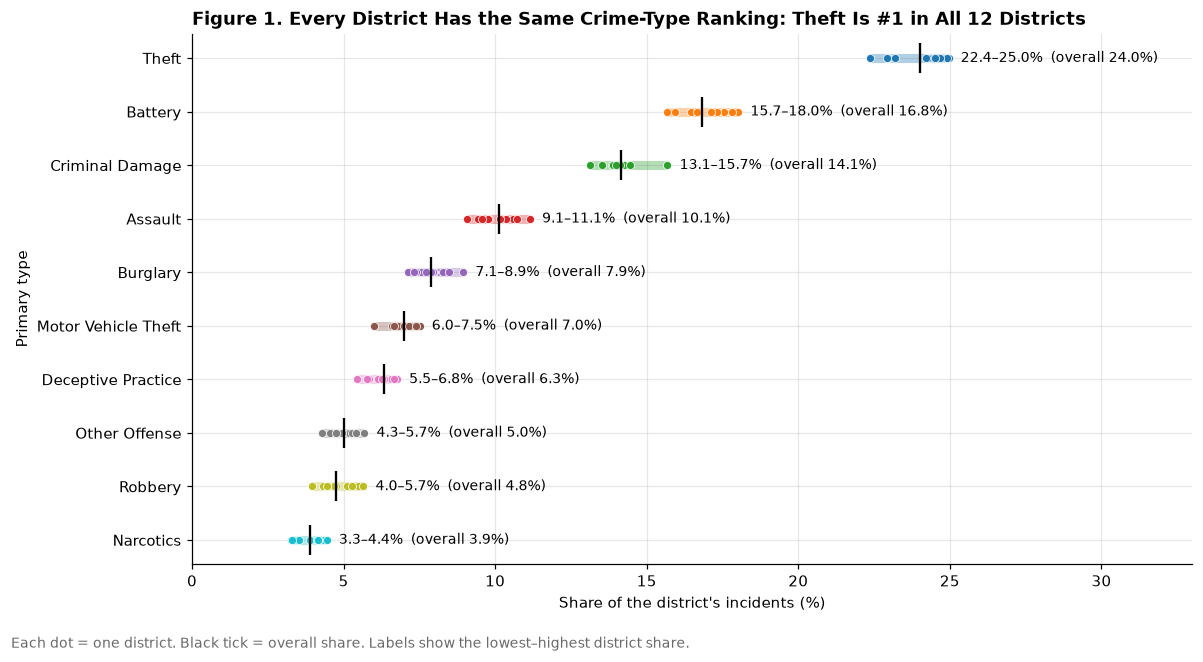

Districts whose top four crime types match the overall top four: 12 of 12
Largest spread between districts for any crime type: 2.6 percentage points (Theft)
Smallest gap between theft and the 2nd-ranked type in any district: 4.9 percentage points

Table 2. Spread of each crime type's share across districts (%)
                     Overall  Lowest district  Highest district  Range (pp)
primary_type                                                               
THEFT                   24.0             22.4              25.0         2.6
BATTERY                 16.8             15.7              18.0         2.3
CRIMINAL DAMAGE         14.1             13.1              15.7         2.6
ASSAULT                 10.1              9.1              11.1         2.1
BURGLARY                 7.9              7.1               8.9         1.8
MOTOR VEHICLE THEFT      7.0              6.0               7.5         1.5
DECEPTIVE PRACTICE       6.3              5.5               6.8         1.3
OTHE

In [52]:
summary = pd.DataFrame({"overall": overall_pct,
                        "low": col_pct.min(axis=1),
                        "high": col_pct.max(axis=1)})
summary["range_pp"] = summary["high"] - summary["low"]

# How many districts share the same top-four ranking as the overall data?
ranks = col_pct.rank(ascending=False, method="min")
same_top4 = sum(list(ranks[d].sort_values().index[:4]) == TYPE_ORDER[:4] for d in ranks.columns)

fig, ax = plt.subplots(figsize=(11, 6))
y = np.arange(len(TYPE_ORDER))[::-1]           # most common type at the top
for yi, crime in zip(y, TYPE_ORDER):
    color = CRIME_COLORS[crime]
    s = summary.loc[crime]
    ax.hlines(yi, s["low"], s["high"], color=color, linewidth=6, alpha=0.35)
    ax.scatter(col_pct.loc[crime], [yi] * col_pct.shape[1], color=color, s=28, zorder=3,
               edgecolor="white", linewidth=0.5)
    ax.scatter(s["overall"], yi, marker="|", s=400, color="black", zorder=4)
    ax.text(s["high"] + 0.4, yi, f"{s['low']:.1f}–{s['high']:.1f}%  (overall {s['overall']:.1f}%)",
            va="center", fontsize=9)
ax.set_yticks(y)
ax.set_yticklabels([label(c) for c in TYPE_ORDER])
ax.set_xlim(0, 33)
ax.set_xlabel("Share of the district's incidents (%)")
ax.set_ylabel("Primary type")
ax.set_title("Figure 1. Every District Has the Same Crime-Type Ranking: Theft Is #1 in All 12 Districts",
             loc="left")
fig.text(0.01, 0.01, "Each dot = one district. Black tick = overall share. Labels show the lowest–highest district share.",
         fontsize=9, color="dimgray")
plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.show()

print(f"Districts whose top four crime types match the overall top four: {same_top4} of 12")
print(f"Largest spread between districts for any crime type: {summary['range_pp'].max():.1f} percentage points "
      f"({label(summary['range_pp'].idxmax())})")
print(f"Smallest gap between theft and the 2nd-ranked type in any district: "
      f"{(col_pct.loc['THEFT'] - col_pct.loc['BATTERY']).min():.1f} percentage points")
print("\nTable 2. Spread of each crime type's share across districts (%)")
print(summary.round(1).rename(columns={"overall": "Overall", "low": "Lowest district",
                                       "high": "Highest district", "range_pp": "Range (pp)"}))

**Figure 1 shows that the four most common crime types have the same ranking across all 12 districts. Theft is the most common crime type in all 12 districts, making up between 22.4% and 25.0% of each district's incidents. In every district, theft is at least 4.9 percentage points ahead of the second most common type, so its first-place ranking is never close. The top four crime types (theft, battery, criminal damage, and assault) appear in the same order in all 12 districts.**

**The figure also shows that the spread between districts is small for every crime type. The widest spread is 2.6 percentage points, for theft and criminal damage, and the narrowest is 1.2 percentage points, for narcotics (Table 2). In other words, no matter which district we look at, about one in four incidents is theft, about one in six is battery, and about one in seven is criminal damage.**

**These findings suggest that the distribution of recorded crime types is relatively consistent across districts, with no substantial differences in the proportions of individual crime categories.**

### (Q1) Figure 2: Are the Differences Between Districts Larger Than Chance?

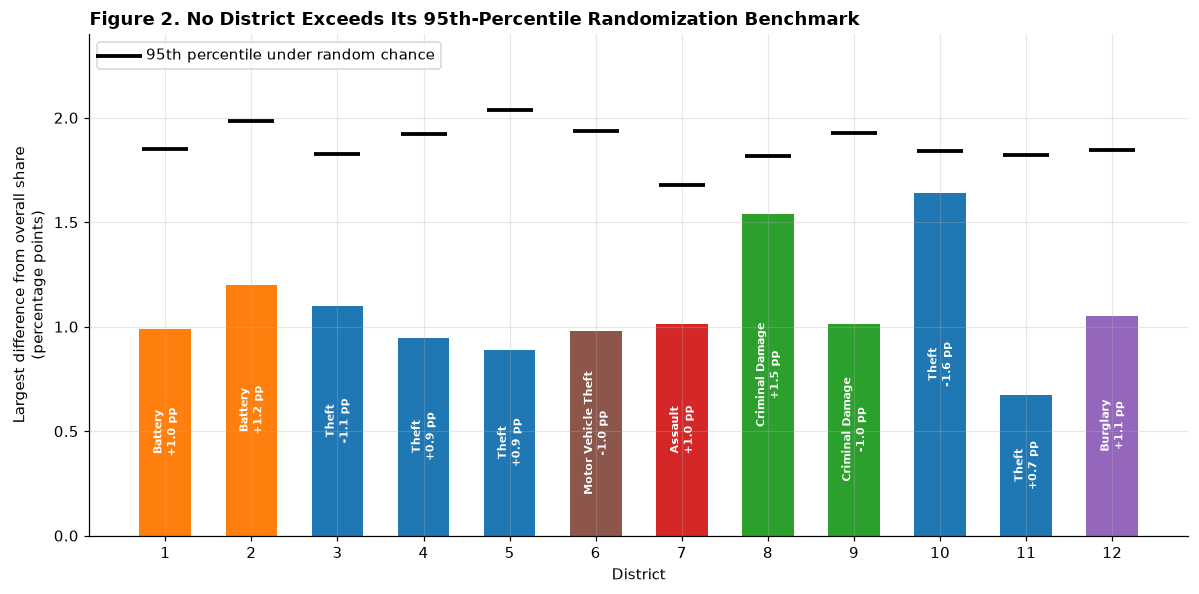

Districts whose largest difference is below the chance level: 12 of 12
Shuffles with an overall largest difference ≥ 1.64 pp: 74%

Chi-square test of independence: chi2 = 93.7, df = 99, p = 0.63
Smallest expected cell count: 76 (test is valid when all are ≥ 5)
Cramér's V = 0.019  (0 = no association, 1 = perfect association)


In [53]:
# For each district: the single largest difference (in percentage points) between its
# crime mix and the overall mix. To judge whether this is "large", we compare it with what
# random chance produces: we shuffle the district labels 1,000 times (keeping each district's
# total) and record the 95th percentile of the same statistic.
diff_pp = col_pct.sub(overall_pct, axis=0)
obs_max = diff_pp.abs().max(axis=0)
obs_type = diff_pp.abs().idxmax(axis=0)
obs_sign = [diff_pp.loc[t, d] for d, t in obs_type.items()]

type_codes = pd.Categorical(df_geo["primary_type"], categories=TYPE_ORDER).codes
dist_cat = pd.Categorical(df_geo["district"].astype(int))
dist_codes = dist_cat.codes
overall_share = np.bincount(type_codes, minlength=len(TYPE_ORDER)) / len(type_codes)

def max_dev_by_district(d_codes):
    m = np.zeros((len(TYPE_ORDER), len(dist_cat.categories)))
    np.add.at(m, (type_codes, d_codes), 1)
    return (np.abs(m / m.sum(axis=0) - overall_share[:, None]) * 100).max(axis=0)

rng = np.random.default_rng(42)          # fixed seed so results are reproducible
sims = np.array([max_dev_by_district(rng.permutation(dist_codes)) for _ in range(1000)])
chance_95 = np.percentile(sims, 95, axis=0)

fig, ax = plt.subplots(figsize=(11, 5.5))
x = np.arange(len(obs_max))
bars = ax.bar(x, obs_max.values, color=[CRIME_COLORS[t] for t in obs_type], width=0.6)
ax.scatter(x, chance_95, marker="_", s=900, color="black", linewidth=2.5, zorder=3,
           label="95th percentile under random chance")
for xi, (b, t, s) in enumerate(zip(bars, obs_type, obs_sign)):
    ax.text(xi, b.get_height() / 2, f"{label(t)}\n{s:+.1f} pp", ha="center", va="center",
            fontsize=7.5, rotation=90, color="white", fontweight="bold")
ax.set_xticks(x)
ax.set_xticklabels([str(d) for d in obs_max.index])
ax.set_ylim(0, 2.4)
ax.set_xlabel("District")
ax.set_ylabel("Largest difference from overall share\n(percentage points)")
ax.set_title("Figure 2. No District Exceeds Its 95th-Percentile Randomization Benchmark", loc="left")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

chi2, p, dof, expected = chi2_contingency(ct)
cramers_v = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))
print(f"Districts whose largest difference is below the chance level: {(obs_max.values < chance_95).sum()} of 12")
print(f"Shuffles with an overall largest difference ≥ {obs_max.max():.2f} pp: "
      f"{(sims.max(axis=1) >= obs_max.max()).mean() * 100:.0f}%")
print(f"\nChi-square test of independence: chi2 = {chi2:.1f}, df = {dof}, p = {p:.2f}")
print(f"Smallest expected cell count: {expected.min():.0f} (test is valid when all are ≥ 5)")
print(f"Cramér's V = {cramers_v:.3f}  (0 = no association, 1 = perfect association)")

**Figure 1 showed that the rankings are the same, but it does not tell us whether the small differences that do exist are meaningful. Figure 2 answers this. For each district, the bar shows the single largest difference between that district's crime mix and the overall mix, and the black line shows how large that difference would be by random chance (the 95th percentile from 1,000 random shuffles of the district labels).**

**The largest difference in the entire dataset is theft in District 10, which is 1.6 percentage points below the overall theft share. In all 12 districts, the largest difference is smaller than the chance level. In fact, 74% of the random shuffles produced a difference at least as large as 1.6 percentage points, so this result is very typical of random variation. The chi-square test agrees: the result was not significant (chi-square = 93.7, df = 99, p = 0.63), and Cramér's V was 0.019, which indicates almost no association. All expected cell counts were at least 76, so the chi-square test is valid for this table.**

### Interpretation

Both figures lead to the same conclusion from two different angles. Figure 1 shows that the crime-type ranking is identical in every district, and Figure 2 shows that the small differences between districts are no larger than what random chance produces. Together, this means that knowing which district an incident occurred in tells us almost nothing about what type of crime it is. Districts differ in how many incidents they record, but not in which types of incidents they record.


### Limitations

This is an instructional dataset rather than real Chicago police records, so this result describes only the provided course data. A finding of "no relationship" in this dataset should not be used to make claims about real districts. In addition, 168 records (0.6%) were excluded because their district was missing, and we compared districts only using counts and percentages, since we do not have population or area data.

### Answer to Research Question 1

The analysis did not find statistically significant evidence of a relationship between crime types and districts in this instructional dataset. All 12 districts share the same ranking of the four most common crime types, and no district differs from the overall crime-type distribution by more than approximately 1.6 percentage points for any individual category. Both the permutation test and the chi-square test (p = 0.63) indicate that the observed differences are consistent with random variation.

## 5.2 Research Question 2: How has the number of recorded crime incidents changed from 2020 through 2024?

### (Q2) Figure 3: Are recorded incidents changing from year to year?

### Purpose

The purpose of this analysis is to examine how the number of recorded crime incidents changed from 2020 through 2024. By comparing the total number of incidents each year, we aim to identify whether recorded incidents increased, decreased, or remained relatively stable over the five-year period. This analysis will help us understand the overall trends in the provided dataset and identify any noticeable changes between years.

### Method 

To answer this research question, we will group the recorded crime incidents by year from 2020 through 2024 and calculate the total number of incidents for each year. We will then compare these annual totals and calculate the percentage change between consecutive years to identify increases or decreases in recorded incidents. Finally, we will visualize the results in a chart to better understand the overall trend throughout the five-year period. Records with missing or invalid dates will be excluded from the yearly analysis. A line chart was selected because the data covers five consecutive years from 2020 through 2024. This visualization makes it easy to compare the number of recorded crime incidents between individual years while also identifying the overall trend across the five-year period.

In [54]:
yearly_counts = df_clean["year"].value_counts().sort_index()

print("Recorded Crime Incidents by Year:")
print(yearly_counts)

Recorded Crime Incidents by Year:
year
2020    5623
2021    5549
2022    5572
2023    5611
2024    5610
Name: count, dtype: Int64


In [55]:
monthly_counts = pd.crosstab(df_time["month"], df_time["year"])

print("Monthly Recorded Crime Incidents by Year:")
print(monthly_counts)

Monthly Recorded Crime Incidents by Year:
year   2020  2021  2022  2023  2024
month                              
1       464   496   493   471   475
2       483   384   411   371   427
3       459   471   459   512   466
4       465   486   473   441   459
5       469   496   461   493   514
6       459   481   484   456   476
7       486   457   440   520   458
8       456   461   517   461   496
9       465   417   423   473   454
10      478   442   463   501   481
11      444   481   481   445   442
12      495   477   467   467   462


In [56]:
yearly_change = yearly_counts.pct_change() * 100

print("Year-over-Year Percentage Change:")
print(yearly_change.round(2))

Year-over-Year Percentage Change:
year
2020    <NA>
2021   -1.32
2022    0.41
2023     0.7
2024   -0.02
Name: count, dtype: Float64


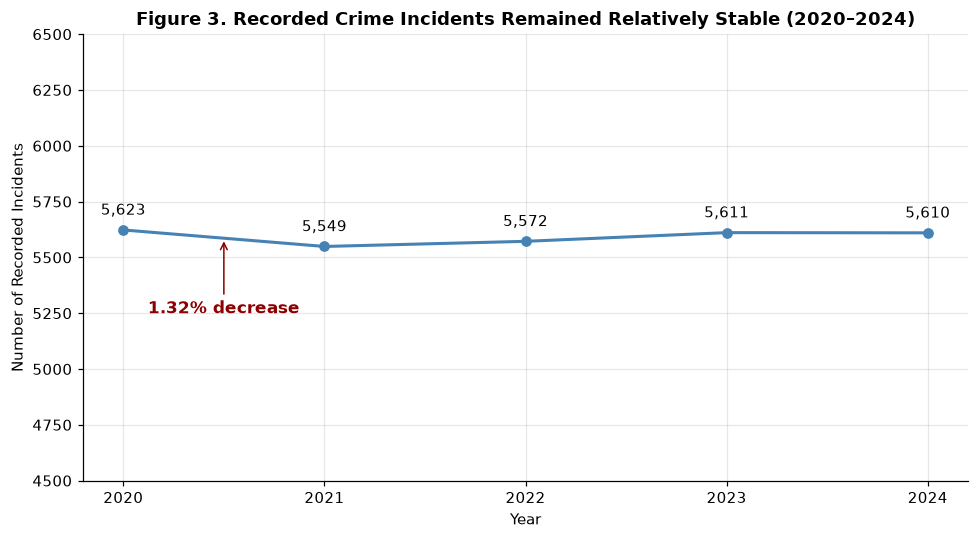

In [57]:
fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    yearly_counts.index,
    yearly_counts.values,
    marker="o",
    linewidth=2,
    color="steelblue"
)

for year, count in yearly_counts.items():
    ax.annotate(
        f"{count:,}",
        (year, count),
        textcoords="offset points",
        xytext=(0, 10),
        ha="center"
    )

ax.annotate(
    "1.32% decrease",
    xy=(2020.5, 5586),
    xytext=(2020.5, 5250),
    ha="center",
    color="darkred",
    fontsize=11,
    fontweight="bold",
    arrowprops=dict(arrowstyle="->", color="darkred")
)

ax.set_title(
    "Figure 3. Recorded Crime Incidents Remained Relatively Stable (2020–2024)"
)

ax.set_xlabel("Year")
ax.set_ylabel("Number of Recorded Incidents")

ax.set_xticks(yearly_counts.index)
ax.set_ylim(4500, 6500)

plt.tight_layout()
plt.show()

**Figure 3 shows that the number of recorded crime incidents remained relatively stable between 2020 and 2024. The largest year-over-year change occurred between 2020 and 2021, when recorded incidents decreased by 1.32%, from 5,623 to 5,549. Following this decrease, recorded incidents increased slightly in 2022 and 2023 before remaining nearly unchanged in 2024. Overall, the number of recorded incidents decreased by approximately 0.23% across the five-year period.**

**Although Figure 3 shows that recorded crime incidents remained relatively stable from 2020 through 2024, this raises another question: Do certain months or seasons consistently experience higher or lower numbers of recorded incidents? While the annual totals show little overall change, there may still be fluctuations within each year that are not visible in the yearly comparison. To investigate this further, Figure 4 will examine monthly recorded crime incidents across all five years.**

### (Q2) Figure 4: Even if yearly totals are stable, are there patterns or fluncuations within each year? 

### Purpose

The purpose of this analysis is to determine whether certain months consistently have higher or lower numbers of recorded crime incidents across the years 2020 through 2024. While Figure 3 showed that the annual number of recorded incidents remained relatively stable, this analysis will investigate whether a similar pattern exists within each year or whether there are noticeable monthly or seasonal fluctuations that the annual totals may have hidden.

### Method 

To conduct this analysis, we will group the recorded crime incidents by month and year from 2020 through 2024 and calculate the total number of incidents for each month. We will then create a line chart with months on the X-axis and the number of recorded incidents on the Y-axis. Each year will be represented by a separate colored line, allowing us to compare monthly changes within individual years as well as identify similarities or differences in monthly patterns across all five years. Records with missing or invalid dates will be excluded from this analysis.

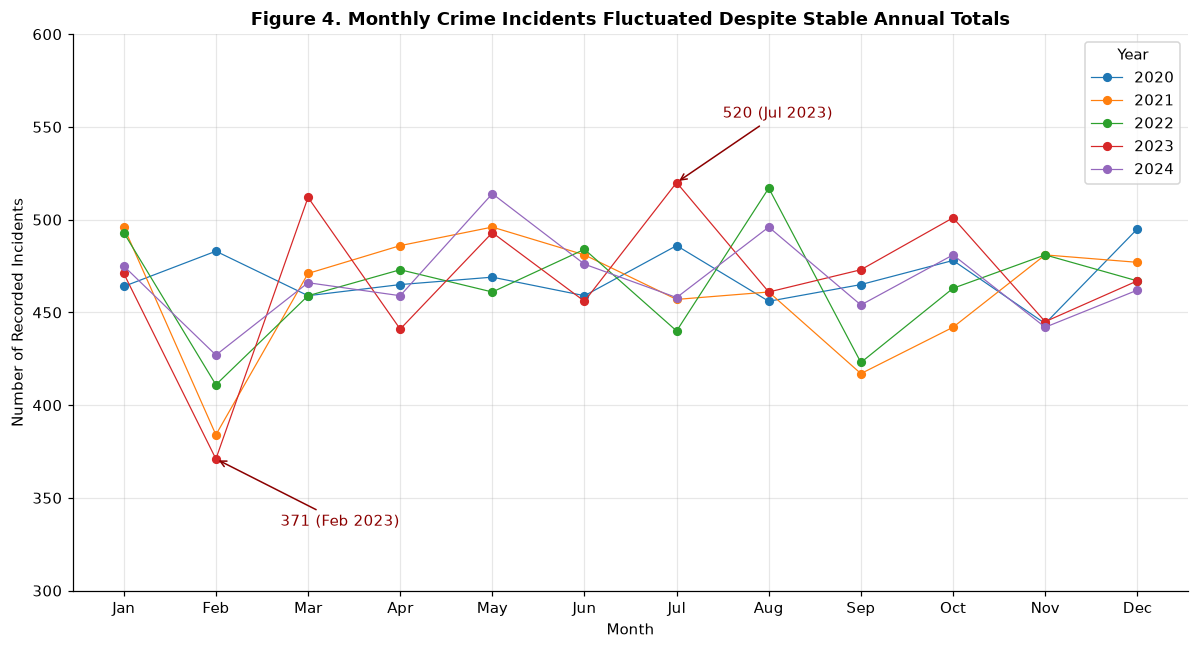


Table 3. Monthly Recorded Crime Incidents by Year:
year   2020  2021  2022  2023  2024
month                              
1       464   496   493   471   475
2       483   384   411   371   427
3       459   471   459   512   466
4       465   486   473   441   459
5       469   496   461   493   514
6       459   481   484   456   476
7       486   457   440   520   458
8       456   461   517   461   496
9       465   417   423   473   454
10      478   442   463   501   481
11      444   481   481   445   442
12      495   477   467   467   462

Table 4. Average Daily Recorded Incidents by Month and Year
year    2020   2021   2022   2023   2024
month                                   
1      14.97  16.00  15.90  15.19  15.32
2      16.66  13.71  14.68  13.25  14.72
3      14.81  15.19  14.81  16.52  15.03
4      15.50  16.20  15.77  14.70  15.30
5      15.13  16.00  14.87  15.90  16.58
6      15.30  16.03  16.13  15.20  15.87
7      15.68  14.74  14.19  16.77  14.77
8      14.71  

In [58]:
fig, ax = plt.subplots(figsize=(11, 6))

for year in monthly_counts.columns:
    ax.plot(
        monthly_counts.index,
        monthly_counts[year],
        marker="o",
        markersize=5,
        linewidth=0.8,
        label=str(year)
    )

ax.annotate(
    "371 (Feb 2023)",
    xy=(2, 371),
    xytext=(2.7, 335),
    arrowprops=dict(arrowstyle="->", color="darkred"),
    fontsize=10,
    color="darkred"
)

ax.annotate(
    "520 (Jul 2023)",
    xy=(7, 520),
    xytext=(7.5, 555),
    arrowprops=dict(arrowstyle="->", color="darkred"),
    fontsize=10,
    color="darkred"
)

ax.set_title(
    "Figure 4. Monthly Crime Incidents Fluctuated Despite Stable Annual Totals"
)

ax.set_xlabel("Month")
ax.set_ylabel("Number of Recorded Incidents")

ax.set_xticks(range(1, 13))
ax.set_xticklabels([
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
])

ax.legend(title="Year")
ax.set_ylim(300, 600)

plt.tight_layout()
plt.show()

# Count recorded incidents by month and year
monthly_counts = pd.crosstab(df_time["month"], df_time["year"])

print("\nTable 3. Monthly Recorded Crime Incidents by Year:")
print(monthly_counts)

# Calculate days in each month
days_in_month = monthly_counts.copy()

for year in monthly_counts.columns:
    for month in monthly_counts.index:
        days_in_month.loc[month, year] = pd.Timestamp(
            year=int(year), month=int(month), day=1
        ).days_in_month

# Calculate average daily incidents
daily_averages = monthly_counts / days_in_month

print("\nTable 4. Average Daily Recorded Incidents by Month and Year")
print(daily_averages.round(2))

**Figure 4 shows that although the total number of recorded crime incidents remained relatively stable from 2020 through 2024, the number of incidents fluctuated between individual months. For example, February 2023 had 371 recorded incidents, while July 2023 had 520, a difference of 149 incidents.**

**Table 3 also shows that February had the lowest number of recorded incidents in four of the five years, with 2020 being the exception. However, because February has fewer days than other months, these lower totals do not necessarily mean a lower daily average of recorded incidents. Table 4 accounts for this by calculating average daily incidents, allowing for a more meaningful comparison between months of different lengths.**

**Another observation from Figure 4 is that the month with the highest number of recorded incidents changes across the five years. December had the highest count in 2020, January and May tied in 2021, August had the highest in 2022, July in 2023, and May in 2024. This suggests that there is no obvious, consistent monthly or seasonal peak across the five-year period. Although monthly incident counts fluctuate, the fluctuations do not follow the same pattern every year.**

### Interpretations 

The biggest takeaway from Figures 3 and 4 is that the number of recorded crime incidents remained relatively stable from 2020 through 2024 when comparing annual totals. Figure 3 shows that the number of incidents ranged from 5,549 to 5,623 per year, with the largest year-over-year change being a 1.32% decrease from 2020 to 2021. Overall, there were only 13 fewer recorded incidents in 2024 compared with 2020.

However, when examining the data more closely in Figure 4, we can see that recorded incidents fluctuate more noticeably from month to month within individual years. For example, February 2023 had 371 recorded incidents, while July 2023 had 520, a difference of 149 incidents.

Although these monthly fluctuations are noticeable, the month with the highest number of incidents changes across the five years. This suggests that there is no obvious, consistent monthly peak throughout the dataset. Tables 3 and 4 also show that differences in the number of days per month can affect comparisons of monthly totals.

Together, these findings demonstrate that relatively stable annual incident totals can hide fluctuations within individual years. However, the analysis does not establish what causes these monthly changes.

### Limitations 

One major limitation of this analysis is that the dataset is a learning tool for this course and was provided for educational purposes rather than representing actual Chicago crime records. Therefore, the findings from Figures 3 and 4 cannot be used to draw conclusions about real-world crime trends in Chicago.

Another limitation is that 35 records were excluded from the time based analysis because they contained missing or invalid dates. Although this represents a small part of the dataset, excluding these records could affect the accuracy of our yearly and monthly totals. This is important because the difference between 2020 and 2024 was only 13 recorded incidents, meaning the missing records could have potentially changed the direction of the overall trend.

Also, our analysis lacks the needed context to explain why monthly incident counts fluctuate. Factors such as seasonal population changes, tourism, or major events could influence the number of recorded incidents. However, without this needed information, we cannot answer whether these factors contributed to the changes seen in Figure 4.

Finally, February has fewer days than most other months, which can influence comparisons of monthly incident totals. Although Table 4 addresses this limitation by calculating average daily incidents, the analysis still cannot establish a consistent seasonal pattern or explain the causes of monthly fluctuations.

### Answer to Question 2

Based on our analysis, the number of recorded crime incidents remained relatively stable from 2020 through 2024. Annual totals ranged from 5,549 to 5,623 incidents, with an overall decrease of only 13 incidents (approximately 0.23%) between 2020 and 2024. Although the yearly totals showed little change, examining the data monthly revealed noticeable fluctuations within individual years. February had the lowest recorded incident count in four of the five years, while the months with the highest counts varied across years. Overall, the findings suggest that annual incident counts remained stable despite monthly variations, with no clear, consistent monthly peak across the five-year period.

## 5.3 Research Question 3: How does the percentage of incidents involving an arrest differ across crime types?

### (Q3) Figure 5: Arrest Percentage by Crime Type

### Purpose

The purpose of this analysis is to find out whether some crime types are more likely to involve an arrest than others, and whether these differences stay consistent over time. This tells us which categories stand out in terms of arrest outcomes in the dataset.


### Method

For each crime type, we calculated the arrest percentage, which is the number of incidents where arrest is True divided by the total number of incidents of that type. We compared each crime type with the overall arrest percentage of all 28,000 incidents (13.8%). To show how precise each percentage is, we calculated a 95% confidence interval. We also used a chi-square test to check whether arrest outcomes are associated with crime type. Finally, we calculated the arrest percentage for each crime type in each year from 2020 to 2024, to check whether the pattern is stable over time.

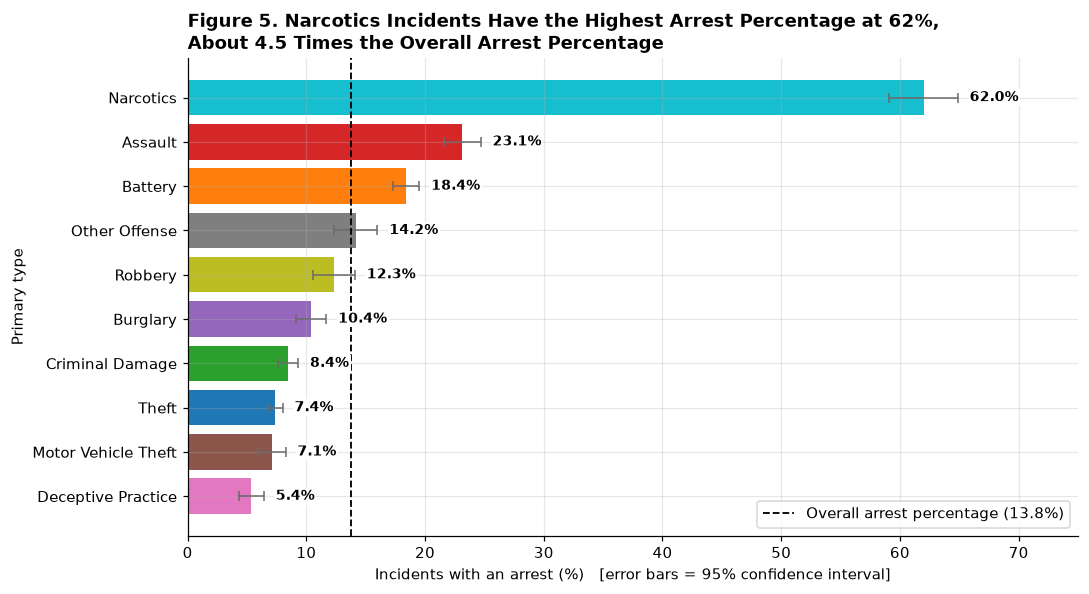

Overall arrest percentage (all 28,000 incidents): 13.8%
Narcotics vs overall: 62.0% / 13.8% = 4.50 times
Narcotics vs all other crime types combined: 62.0% / 11.8% = 5.24 times
Narcotics vs the second-highest type (assault): 2.68 times
Highest vs lowest type: 62.0% vs 5.4% (Deceptive Practice), a gap of 56.6 percentage points

Chi-square test (crime type × arrest): chi2 = 2958.6, df = 9, p < 0.001, Cramér's V = 0.325

Table 5. Arrests by crime type with 95% confidence intervals


,incidents,arrests,pct,ci_low,ci_high
primary_type,,,,,
NARCOTICS,1092,677,62.0,59.1,64.9
ASSAULT,2832,655,23.1,21.6,24.7
BATTERY,4720,869,18.4,17.3,19.5
OTHER OFFENSE,1405,199,14.2,12.3,16.0
ROBBERY,1331,164,12.3,10.6,14.1
BURGLARY,2210,230,10.4,9.1,11.7
CRIMINAL DAMAGE,3966,335,8.4,7.6,9.3
THEFT,6720,496,7.4,6.8,8.0
MOTOR VEHICLE THEFT,1956,139,7.1,6.0,8.2


In [59]:
arrest = (df_clean.groupby("primary_type")["arrest"]
          .agg(incidents="size", arrests="sum", pct="mean"))
arrest["pct"] *= 100
se = np.sqrt(arrest["pct"] / 100 * (1 - arrest["pct"] / 100) / arrest["incidents"]) * 100
arrest["ci_low"] = arrest["pct"] - 1.96 * se
arrest["ci_high"] = arrest["pct"] + 1.96 * se
arrest = arrest.sort_values("pct")

overall_arrest = df_clean["arrest"].mean() * 100
other_arrest = df_clean.loc[df_clean["primary_type"] != "NARCOTICS", "arrest"].mean() * 100
narc = arrest.loc["NARCOTICS", "pct"]

fig, ax = plt.subplots(figsize=(10, 5.5))
bars = ax.barh([label(c) for c in arrest.index], arrest["pct"],
               color=[CRIME_COLORS[c] for c in arrest.index],
               xerr=[arrest["pct"] - arrest["ci_low"], arrest["ci_high"] - arrest["pct"]],
               error_kw={"ecolor": "dimgray", "capsize": 3, "linewidth": 1})
for yi, (pct, hi) in enumerate(zip(arrest["pct"], arrest["ci_high"])):
    ax.text(hi + 1, yi, f"{pct:.1f}%", va="center", fontsize=9, fontweight="bold",
            bbox={"facecolor": "white", "edgecolor": "none", "pad": 1})
ax.axvline(overall_arrest, color="black", linestyle="--", linewidth=1.2,
           label=f"Overall arrest percentage ({overall_arrest:.1f}%)")
ax.set_xlim(0, 75)
ax.set_xlabel("Incidents with an arrest (%)   [error bars = 95% confidence interval]")
ax.set_ylabel("Primary type")
ax.set_title(f"Figure 5. Narcotics Incidents Have the Highest Arrest Percentage at {narc:.0f}%,\n"
             f"About {narc / overall_arrest:.1f} Times the Overall Arrest Percentage", loc="left")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

print(f"Overall arrest percentage (all 28,000 incidents): {overall_arrest:.1f}%")
print(f"Narcotics vs overall: {narc:.1f}% / {overall_arrest:.1f}% = {narc / overall_arrest:.2f} times")
print(f"Narcotics vs all other crime types combined: {narc:.1f}% / {other_arrest:.1f}% = {narc / other_arrest:.2f} times")
print(f"Narcotics vs the second-highest type (assault): {narc / arrest.loc['ASSAULT', 'pct']:.2f} times")
print(f"Highest vs lowest type: {narc:.1f}% vs {arrest['pct'].min():.1f}% "
      f"({label(arrest['pct'].idxmin())}), a gap of {narc - arrest['pct'].min():.1f} percentage points")

chi2_a, p_a, dof_a, _ = chi2_contingency(pd.crosstab(df_clean["primary_type"], df_clean["arrest"]))
v_a = np.sqrt(chi2_a / len(df_clean))
print(f"\nChi-square test (crime type × arrest): chi2 = {chi2_a:.1f}, df = {dof_a}, p < 0.001, Cramér's V = {v_a:.3f}")

print("\nTable 5. Arrests by crime type with 95% confidence intervals")
arrest.sort_values("pct", ascending=False).round(1)

**Figure 5 shows that narcotics has by far the highest arrest percentage: 677 of the 1,092 narcotics incidents (62.0%) involved an arrest. This is about 4.5 times the overall arrest percentage of 13.8%. If narcotics is compared with all other crime types combined (11.8%), the difference is about 5.2 times. Narcotics is also 2.7 times higher than the second-highest crime type, assault (23.1%).**

**Four crime types have arrest percentages above the overall percentage of 13.8%: narcotics (62.0%), assault (23.1%), battery (18.4%), and other offense (14.2%). However, other offense is only slightly above the overall percentage.**

**The 95% confidence intervals in Table 5 provide additional context for the differences in arrest percentages across crime types. The narcotics interval (59.1%–64.9%) is far above every other crime type, and the intervals for assault (21.6%–24.7%) and battery (17.3%–19.5%) do not overlap with each other or with any lower category. The chi-square test provides strong statistical evidence of an association between crime type and arrest (chi-square = 2,958.6, df = 9, p < 0.001, Cramér's V = 0.325). However, the intervals for theft, motor vehicle theft, and criminal damage overlap, so we do not claim that the small differences among these lower categories are meaningful.**

### Figure 6: Is the Arrest Pattern Stable from 2020-2024?

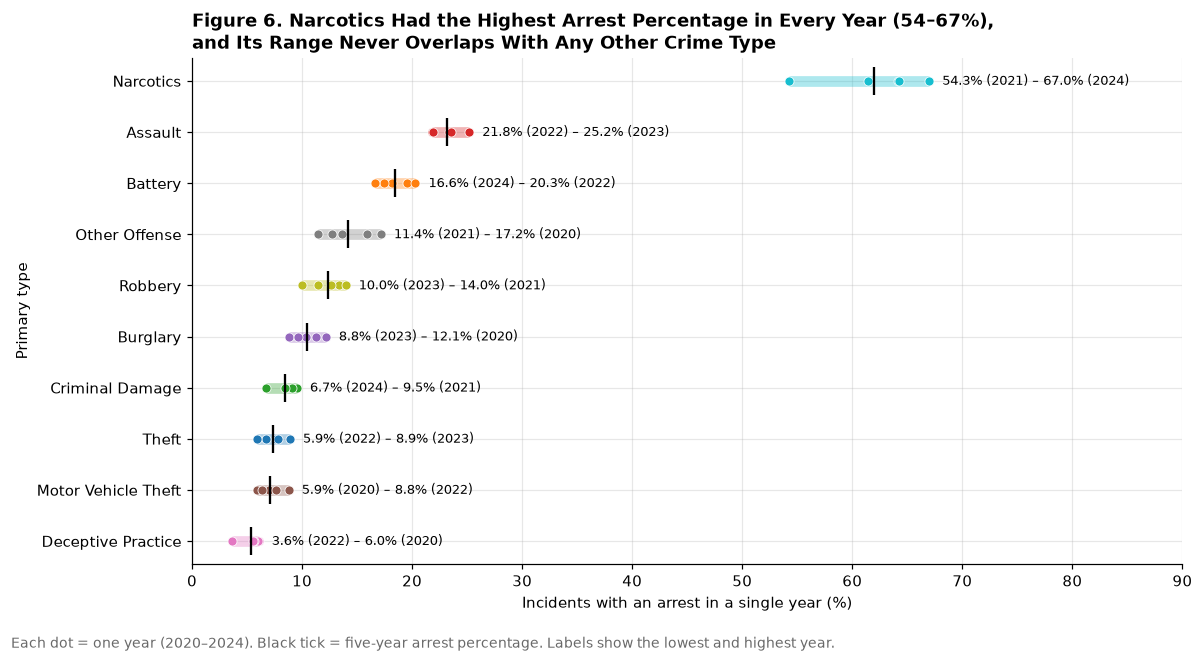

Narcotics' lowest year is 29.1 percentage points above the highest year of any other type
Types ranked in the same position every year: ['Narcotics', 'Assault', 'Battery']

Table 6. Arrest percentage by crime type and year (%)
year                 2020  2021  2022  2023  2024
primary_type                                     
NARCOTICS            64.2  54.3  64.2  61.4  67.0
ASSAULT              23.4  23.5  21.8  25.2  21.9
BATTERY              19.5  18.2  20.3  17.4  16.6
OTHER OFFENSE        17.2  11.4  13.6  12.7  15.9
ROBBERY              13.4  14.0  12.7  10.0  11.5
BURGLARY             12.1  11.3  10.4   8.8   9.7
CRIMINAL DAMAGE       8.5   9.5   9.1   8.5   6.7
THEFT                 7.6   6.7   5.9   8.9   7.8
MOTOR VEHICLE THEFT   5.9   7.0   8.8   7.7   6.3
DECEPTIVE PRACTICE    6.0   6.0   3.6   5.7   5.5

Table 7. Rank of each crime type in each year (1 = highest arrest percentage)


year,2020,2021,2022,2023,2024
primary_type,,,,,
NARCOTICS,1,1,1,1,1
ASSAULT,2,2,2,2,2
BATTERY,3,3,3,3,3
OTHER OFFENSE,4,5,4,4,4
ROBBERY,5,4,5,5,5
BURGLARY,6,6,6,7,6
CRIMINAL DAMAGE,7,7,7,8,8
THEFT,8,9,9,6,7
MOTOR VEHICLE THEFT,10,8,8,9,9


In [60]:
arrest_year = pd.crosstab(df_time["primary_type"], df_time["year"],
                          values=df_time["arrest"], aggfunc="mean") * 100
avg_order = arrest.sort_values("pct").index            # lowest at bottom, highest at top
arrest_year = arrest_year.loc[avg_order]
years = arrest_year.columns

fig, ax = plt.subplots(figsize=(11, 6))
for yi, crime in enumerate(avg_order):
    row = arrest_year.loc[crime]
    color = CRIME_COLORS[crime]
    ax.hlines(yi, row.min(), row.max(), color=color, linewidth=7, alpha=0.35)
    ax.scatter(row.values, [yi] * len(row), color=color, s=35, zorder=3, edgecolor="white", linewidth=0.5)
    ax.scatter(arrest.loc[crime, "pct"], yi, marker="|", s=350, color="black", zorder=4)
    ax.text(row.max() + 1.2, yi,
            f"{row.min():.1f}% ({row.idxmin()}) – {row.max():.1f}% ({row.idxmax()})",
            va="center", fontsize=8.5)
ax.set_yticks(range(len(avg_order)))
ax.set_yticklabels([label(c) for c in avg_order])
ax.set_xlim(0, 90)
ax.set_xlabel("Incidents with an arrest in a single year (%)")
ax.set_ylabel("Primary type")
ax.set_title("Figure 6. Narcotics Had the Highest Arrest Percentage in Every Year (54–67%),\n"
             "and Its Range Never Overlaps With Any Other Crime Type", loc="left")
fig.text(0.01, 0.01, "Each dot = one year (2020–2024). Black tick = five-year arrest percentage. "
         "Labels show the lowest and highest year.", fontsize=9, color="dimgray")
plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.show()

rank_by_year = arrest_year.rank(ascending=False).astype(int).loc[avg_order[::-1]]
gap = arrest_year.loc["NARCOTICS"].min() - arrest_year.drop(index="NARCOTICS").max().max()
print(f"Narcotics' lowest year is {gap:.1f} percentage points above the highest year of any other type")
print("Types ranked in the same position every year:",
      [label(c) for c in rank_by_year.index if rank_by_year.loc[c].nunique() == 1])
print("\nTable 6. Arrest percentage by crime type and year (%)")
print(arrest_year.loc[avg_order[::-1]].round(1))
print("\nTable 7. Rank of each crime type in each year (1 = highest arrest percentage)")
rank_by_year

**Figure 5 combines all five years, so it could hide changes over time. Figure 6 shows each crime type's yearly arrest percentages as dots, with the range from its lowest to its highest year. The narcotics arrest percentage ranged from 54.3% (2021) to 67.0% (2024). Even in its lowest year, narcotics was 29.1 percentage points higher than the highest single year of any other crime type (assault at 25.2% in 2023), so its range never overlaps with any other category.**

**Table 7 shows that narcotics, assault, and battery ranked first, second, and third in every year from 2020 to 2024. The rankings of the lower categories changed more from year to year. For example, theft ranked anywhere from 6th to 9th. These categories have lower and more similar arrest percentages, so relatively small changes can affect their rankings. Narcotics also has substantially fewer recorded incidents per year than theft (approximately 190–250 compared with 1,300–1,400), meaning its annual arrest percentages may be more sensitive to changes in the number of incidents involving an arrest.**

### Interpretation

The two figures show that arrest percentages differ strongly and consistently by crime type. Figure 5 shows the size of the differences across all five years combined, and Figure 6 shows that the most important differences are present in every single year. The main finding is that narcotics incidents have a much higher recorded arrest percentage than any other crime type, followed by assault and battery. Theft, motor vehicle theft, and deceptive practice have some of the lowest arrest percentages. Since the top three positions never change from year to year, this pattern is consistent throughout the five-year period examined.

### Limitations

These results show an association between crime type and arrest, not a cause. Our dataset does not include information on how incidents were reported, how they were investigated, or why an arrest was or was not made, so we cannot explain why arrest percentages differ between crime types. In addition, the arrest column only shows whether an arrest was recorded for the incident, so it should not be interpreted as a measure of police performance or of how often offenders are caught. Finally, this is an instructional dataset rather than real Chicago police records, so these findings describe only the provided course data.

### Answer to Question 3

Arrest percentages differ strongly across crime types. Narcotics has the highest arrest percentage at 62.0%, about 4.5 times the overall arrest percentage of 13.8%, followed by assault (23.1%) and battery (18.4%). Theft (7.4%), motor vehicle theft (7.1%), and deceptive practice (5.4%) have the lowest arrest percentages. Narcotics, assault, and battery held the top three positions in every year from 2020 to 2024, so the pattern is consistent over time.